Loan Approval Prediction Using Decision Tree Classifier

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

Create and Load the Loan Dataset

In [2]:
# Create a sample loan dataset
data = {
    'Income': [30000, 50000, 70000, 25000, 90000, 60000,
               35000, 80000, 45000, 75000, 20000, 65000,
               55000, 40000, 85000, 28000, 72000, 48000,
               95000, 32000],

    'Credit_Score': [550, 650, 750, 500, 800, 700,
                     580, 780, 620, 760, 480, 720,
                     680, 600, 790, 520, 740, 640,
                     820, 560],

    'Employment': [0, 1, 1, 0, 1, 1, 0, 1, 1, 1,
                   0, 1, 1, 0, 1, 0, 1, 1, 1, 0],

    'Loan_Amount': [20000, 25000, 30000, 15000, 40000,
                    25000, 18000, 35000, 22000, 30000,
                    12000, 28000, 26000, 20000, 38000,
                    14000, 32000, 24000, 45000, 16000],

    'Loan_Approval': [0, 1, 1, 0, 1, 1, 0, 1, 1, 1,
                      0, 1, 1, 0, 1, 0, 1, 1, 1, 0]
}

df = pd.DataFrame(data)

# Display dataset information
print("Dataset shape:", df.shape)
print("\nFirst five records:")
print(df.head())

Dataset shape: (20, 5)

First five records:
   Income  Credit_Score  Employment  Loan_Amount  Loan_Approval
0   30000           550           0        20000              0
1   50000           650           1        25000              1
2   70000           750           1        30000              1
3   25000           500           0        15000              0
4   90000           800           1        40000              1


3. Separate Input Features and Target Labels

In [3]:
# Select input features
X = df[['Income', 'Credit_Score', 'Employment', 'Loan_Amount']]

# Select target variable
y = df['Loan_Approval']

print("Input features:", X.shape)
print("Target labels:", y.shape)

Input features: (20, 4)
Target labels: (20,)


4. Split the Dataset into Training and Testing Sets

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

5. Create and Train the Decision Tree Classifier

In [5]:
# Create Decision Tree model
model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


6. Make Predictions

In [6]:
# Predict loan approval
y_pred = model.predict(X_test)

print("Predicted classes:", y_pred)
print("Actual classes:", y_test.values)

Predicted classes: [1 0 1 1]
Actual classes: [1 0 1 1]


7. Evaluate the Performance of the Model

A. Calculate Accuracy

In [8]:
accuracy = accuracy_score(y_test, y_pred)

print("Decision Tree Accuracy:", accuracy * 100, "%")

Decision Tree Accuracy: 100.0 %


B. Display the Confusion Matrix

In [9]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[1 0]
 [0 3]]


C. Display the Classification Report

In [10]:
report = classification_report(
    y_test,
    y_pred,
    target_names=['Rejected', 'Approved'],
    zero_division=0
)

print("Classification Report:")
print(report)

Classification Report:
              precision    recall  f1-score   support

    Rejected       1.00      1.00      1.00         1
    Approved       1.00      1.00      1.00         3

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



8. Visualize the Decision Tree

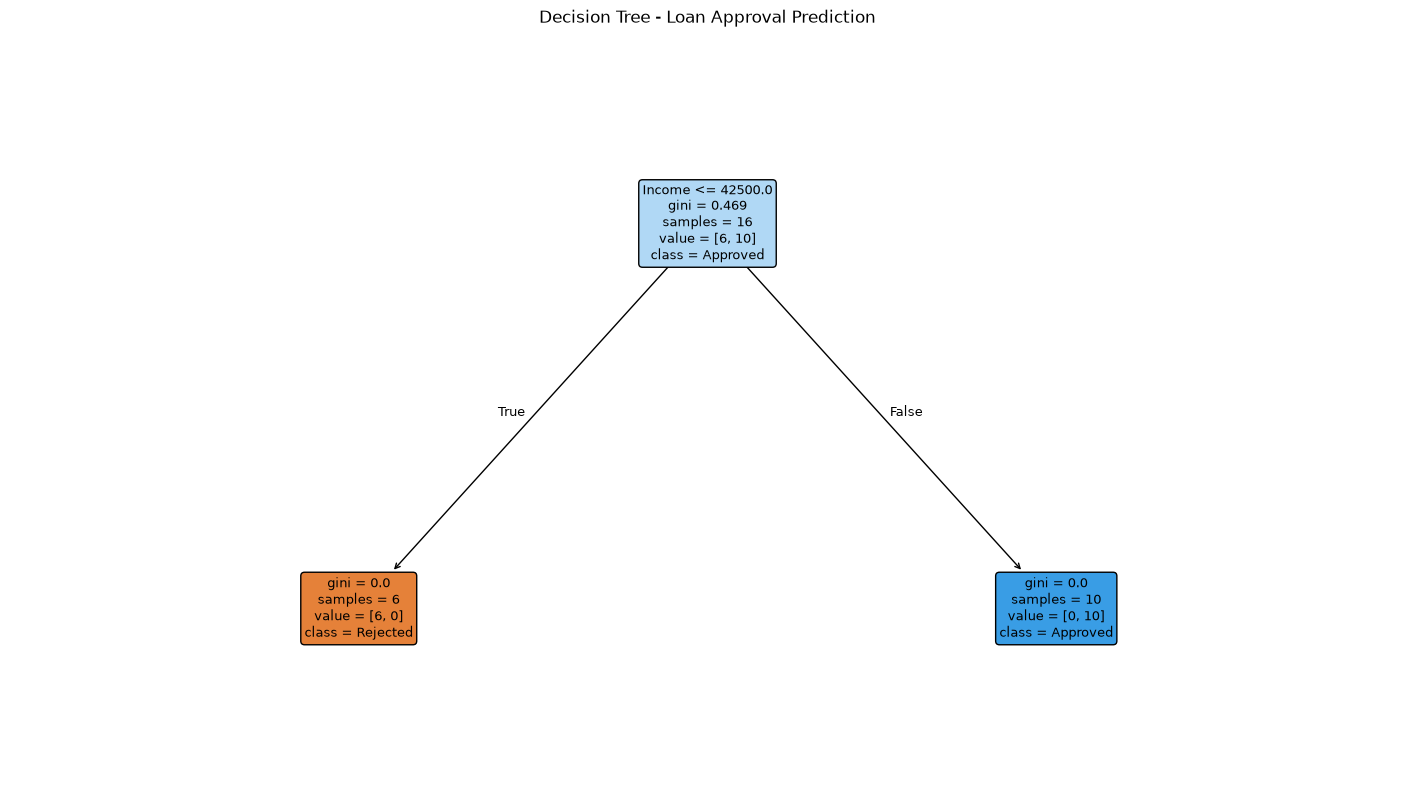

In [11]:
plt.figure(figsize=(18, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=['Rejected', 'Approved'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree - Loan Approval Prediction")

plt.show()